# 都道府県によって医師の多さに違いはあるのか
**氏名：＿＿＿＿＿＿＿＿**

## 1. 調べる問い
都道府県によって、人口10万人当たりの医師数にはどのくらい違いがあるのかを調べる。医師の総数だけを比べると人口が多い都道府県ほど多くなりやすいため、人口10万人当たりの人数に換算して比較する。

## 2. 使用したデータと方法
授業で配布された `japan.csv` を使用する。47都道府県の総人口と医師数を使う。Pythonのpandasでデータを読み込み、`head()`、`info()`、`describe()`で内容を確認する。また、`for`ループで各都道府県の医師数を人口10万人当たりに換算し、平均値の計算や平均を上回る都道府県の抽出を行う。

※このNotebookと同じフォルダにCSVファイルを置いて実行する。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# CSVファイルを読み込む
df = pd.read_csv("japan.csv", encoding="utf-8")

# データの最初の5行を確認する
display(df.head())

# データの列や欠損値などを確認する
df.info()

# 数値データの基本統計量を確認する
display(df[["総人口", "医師数"]].describe())

,Prefecture,都道府県,総人口,日本人人口,15歳未満人口,15～64歳人口,65歳以上人口,外国人人口,出生数,合計特殊出生率,死亡数,転入者数（日本人移動者）,転出者数（日本人移動者）,一般世帯数,一般世帯人員数,単独世帯数,婚姻件数,離婚件数,総面積（北方地域及び竹島を除く）,可住地面積,自然公園面積,県内総生産額（平成27年基準）,県民所得（平成27年基準）,1人当たり県民所得（平成27年基準）,事業所数（民営）,事業所数（民営）（建設業）,事業所数（民営）（製造業）,事業所数（民営）（情報通信業）,事業所数（民営）（卸売業、小売業）,事業所数（民営）（宿泊業、飲食サービス業）,事業所数（民営）（生活関連サービス業、娯楽業）,事業所数（民営）（医療、福祉）,従業者数（民営）,従業者数（民営）（建設業）,従業者数（民営）（製造業）,従業者数（民営）（情報通信業）,従業者数（民営）（卸売業、小売業）,従業者数（民営）（宿泊業、飲食サービス業）,従業者数（民営）（生活関連サービス業、娯楽業）,従業者数（民営）（医療、福祉）,...,高等学校生徒数,短期大学数,大学数,短期大学学生数,大学学生数,公民館数,図書館数,博物館数,劇場、音楽堂等数,社会体育施設数,民間体育施設数,映画館数,一般旅券発行件数,延べ宿泊者数,外国人延べ宿泊者数,総住宅数,空き家数,持ち家数,一戸建住宅数,1住宅当たり延べ面積,総人口（非水洗化人口＋水洗化人口）,非水洗化人口,ごみ総排出量（総量）,1人1日当たりの排出量,ごみのリサイクル率,小売店数,飲食店数,大型小売店数,一般病院数,一般診療所数,歯科診療所数,医師数,歯科医師数,薬剤師数,保育所等数,保育所等在所児数,消費支出（二人以上の世帯）,食料費（二人以上の世帯）,住居費（二人以上の世帯）,教養娯楽費（二人以上の世帯）
0,Hokkaido,北海道,5140000,5098000,530000,2924000,1686000,34321,28762,1.20,69023,49084,53107,2469063,5032739,999825,19326,8662,7842075,2269856,880179,20464601,14892428,2832,216124,21256,10246,2544,51407,27724,18627,19946,2165390,183261,187396,44321,456909,186116,85622,352552,...,112146,15,37,3531,80309,364,165,66,74,3728,1151,19,27026,24664930,741410,2807200,379800,1359400,1255600,91.23,5185414,278541,1781315,941,23.5,36512,22170,822,471,3400,2818,13731,4418,11802,1075,76885,277737,73037,24873,27234
1,Aomori,青森県,1204000,1198000,123000,663000,419000,5409,6513,1.31,18785,16247,20624,509649,1191534,168917,3736,1783,964595,325350,114187,4533207,3291805,2628,55113,5642,2695,390,14097,6755,5978,5112,498418,50709,60863,6018,106856,36321,21542,77912,...,29349,5,10,913,15398,242,35,5,21,697,178,7,3376,3440670,28190,592400,88700,352800,377200,121.58,1246157,153777,455539,1002,14.2,10663,5570,169,76,870,505,2773,735,2345,472,30738,249660,73725,10541,20068
2,Iwate,岩手県,1181000,1173000,125000,648000,408000,6937,6472,1.30,17631,15555,19933,490828,1174106,163290,3673,1459,1527501,375137,72242,4847594,3408836,2781,54598,5292,3483,433,13678,6058,5450,4971,518167,48016,90009,5521,104817,36772,20788,75788,...,29237,4,6,726,11100,174,47,21,27,867,167,8,3659,4268160,22640,579300,93500,338100,352600,119.90,1209697,252040,401035,908,17.1,10434,4769,195,77,888,557,2700,1016,2536,393,28580,285815,77251,18814,25733
3,Miyagi,宮城県,2280000,2256000,258000,1363000,659000,19453,13761,1.15,25897,44528,43566,980549,2251390,362255,8595,3228,728229,318591,171201,9829354,6802912,2943,95305,10458,5087,1145,25004,10306,8298,8116,1031186,96921,121586,21406,224589,78542,37880,134033,...,54112,5,14,2662,49397,434,35,17,42,844,449,11,11763,7625860,59120,1089300,130500,554300,527500,97.24,2269119,193460,808078,976,15.7,16668,8384,375,109,1713,1051,5950,1896,5502,506,40519,287781,78589,22951,26516
4,Akita,秋田県,930000,926000,86000,484000,359000,3651,4335,1.22,16019,10348,13306,383531,923812,117169,2618,1043,1163752,323329,123801,3624750,2637599,2713,44883,4857,3127,282,11368,4976,5265,3851,398671,37900,64599,3374,82750,28088,16828,68859,...,21100,4,7,593,8796,315,49,11,22,857,197,4,2516,2375650,11680,445700,60800,296500,306200,131.93,958311,167201,345947,989,14.6,8797,3908,156,50,822,427,2444,619,2066,272,21915,275545,73628,13191,24327


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 92 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Prefecture               47 non-null     object 
 1   都道府県                     47 non-null     object 
 2   総人口                      47 non-null     int64  
 3   日本人人口                    47 non-null     int64  
 4   15歳未満人口                  47 non-null     int64  
 5   15～64歳人口                 47 non-null     int64  
 6   65歳以上人口                  47 non-null     int64  
 7   外国人人口                    47 non-null     int64  
 8   出生数                      47 non-null     int64  
 9   合計特殊出生率                  47 non-null     float64
 10  死亡数                      47 non-null     int64  
 11  転入者数（日本人移動者）             47 non-null     int64  
 12  転出者数（日本人移動者）             47 non-null     int64  
 13  一般世帯数                    47 non-null     int64  
 14  一般世帯人員数                  47 

,総人口,医師数
count,4.700000e+01,47.000000
mean,2.658426e+06,7226.021277
std,2.793536e+06,8244.770621
min,5.440000e+05,1871.000000
25%,1.046500e+06,2855.500000
50%,1.563000e+06,4298.000000
75%,2.655000e+06,7047.500000
max,1.403800e+07,48072.000000


## 3. 人口10万人当たりの医師数を計算する
医師数を総人口で割り、10万人を掛ける。計算結果をリストに保存する。この処理で`for`ループを使う。

In [2]:
doctor_rates = []

for i in range(len(df)):
    rate = df.loc[i, "医師数"] / df.loc[i, "総人口"] * 100000
    doctor_rates.append(rate)

df["人口10万人当たりの医師数"] = doctor_rates

# 計算結果の一部を表示する
display(df[["都道府県", "総人口", "医師数", "人口10万人当たりの医師数"]].head())

,都道府県,総人口,医師数,人口10万人当たりの医師数
0,北海道,5140000,13731,267.140078
1,青森県,1204000,2773,230.315615
2,岩手県,1181000,2700,228.619814
3,宮城県,2280000,5950,260.964912
4,秋田県,930000,2444,262.795699


## 4. 平均値と平均を上回る都道府県を調べる
次に、`for`ループで47都道府県の医師数（人口10万人当たり）を合計し、平均値を求める。さらに、平均値を上回る都道府県を条件によって選ぶ。

In [3]:
total_rate = 0

for rate in doctor_rates:
    total_rate += rate

average_rate = total_rate / len(doctor_rates)
print("人口10万人当たりの医師数の平均:", round(average_rate, 1), "人")

# 平均を上回る都道府県をforループとif文で選ぶ
above_average = []

for i in range(len(df)):
    if doctor_rates[i] > average_rate:
        above_average.append(df.loc[i, "都道府県"])

print("平均を上回る都道府県の数:", len(above_average))
print("平均を上回る都道府県:")
for prefecture in above_average:
    print(prefecture)

人口10万人当たりの医師数の平均: 278.1 人
平均を上回る都道府県の数: 23
平均を上回る都道府県:
東京都
富山県
石川県
京都府
大阪府
兵庫県
奈良県
和歌山県
鳥取県
島根県
岡山県
広島県
山口県
徳島県
香川県
愛媛県
高知県
福岡県
佐賀県
長崎県
熊本県
大分県
鹿児島県


## 5. 医師数が多い都道府県・少ない都道府県
人口10万人当たりの医師数を基準にして、上位5都道府県と下位5都道府県を表示する。

In [4]:
sorted_df = df.sort_values("人口10万人当たりの医師数", ascending=False)

print("【上位5都道府県】")
display(sorted_df[["都道府県", "人口10万人当たりの医師数"]].head(5).round(1))

print("【下位5都道府県】")
display(sorted_df[["都道府県", "人口10万人当たりの医師数"]].tail(5).sort_values(
    "人口10万人当たりの医師数"
).round(1))

【上位5都道府県】


,都道府県,人口10万人当たりの医師数
35,徳島県,364.6
25,京都府,359.1
30,鳥取県,343.9
41,長崎県,342.9
12,東京都,342.4


【下位5都道府県】


,都道府県,人口10万人当たりの医師数
10,埼玉県,185.4
7,茨城県,205.6
11,千葉県,213.8
6,福島県,221.1
14,新潟県,223.1


## 6. グラフで比較する
上位5都道府県と下位5都道府県を棒グラフで比較する。

/tmp/ipykernel_377/132756988.py:11: UserWarning: Glyph 24499 (\N{CJK UNIFIED IDEOGRAPH-5FB3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377/132756988.py:11: UserWarning: Glyph 23798 (\N{CJK UNIFIED IDEOGRAPH-5CF6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377/132756988.py:11: UserWarning: Glyph 30476 (\N{CJK UNIFIED IDEOGRAPH-770C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377/132756988.py:11: UserWarning: Glyph 20140 (\N{CJK UNIFIED IDEOGRAPH-4EAC}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377/132756988.py:11: UserWarning: Glyph 37117 (\N{CJK UNIFIED IDEOGRAPH-90FD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377/132756988.py:11: UserWarning: Glyph 24220 (\N{CJK UNIFIED IDEOGRAPH-5E9C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377/132756988.py:11: UserWarning: Glyph 40165 (\N{CJK UNIFIED IDEOGRAPH-9CE5}) missing from

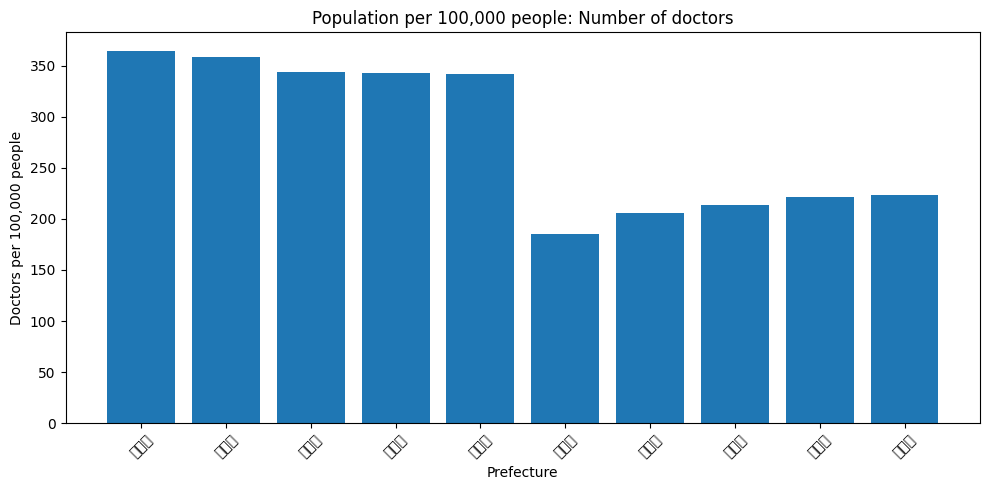

In [5]:
top5 = sorted_df.head(5)
bottom5 = sorted_df.tail(5).sort_values("人口10万人当たりの医師数")
plot_df = pd.concat([top5, bottom5])

plt.figure(figsize=(10, 5))
plt.bar(plot_df["都道府県"], plot_df["人口10万人当たりの医師数"])
plt.title("Population per 100,000 people: Number of doctors")
plt.xlabel("Prefecture")
plt.ylabel("Doctors per 100,000 people")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. 分析結果・わかったこと
今回のデータでは、人口10万人当たりの医師数の47都道府県の平均は約278.1人だった。平均を上回ったのは23都道府県だった。上位は徳島県（約364.6人）、京都府（約359.1人）、鳥取県（約343.9人）で、下位は埼玉県（約185.4人）、茨城県（約205.6人）、千葉県（約213.8人）だった。

この結果から、医師の総数だけでなく人口に対する割合で比べると、都道府県によって医師の多さに差があることがわかった。人口が多い地域が必ずしも人口当たりの医師数も多いわけではない。なお、人口当たりの人数だけでは、医師の専門分野や病院の場所、患者の年齢構成まではわからないため、医療の受けやすさを完全に判断できるわけではない。

## 8. 使用した方法
pandasでCSVを読み込み、データの確認と表の作成を行った。計算・合計・条件による抽出にはPythonの`for`ループと`if`文を使い、グラフはmatplotlibで作成した。

**データ出典：** 授業で配布された `japan.csv`